# 03 · Point-in-time fundamentals

Each company's latest full fiscal year whose 10-K was **filed** on or before the as-of date (never the period end, which would leak data that wasn't public yet). Ratios are ranked as percentiles within each segment.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import fundamentals
res = fundamentals.compute()
pd.Series(res['definitions'])

capex_intensity                                   Capex / revenue
reinvestment_rate                     Capex / operating cash flow
fcf_yield              (Operating cash flow - capex) / market cap
debt_to_capital                Total debt / (total debt + equity)
payout_ratio         (Dividends + buybacks) / operating cash flow
dtype: object

In [3]:
comp = pd.DataFrame(res['companies']).T
comp[['segment','fiscal_year_end', *res['definitions']]]

,segment,fiscal_year_end,capex_intensity,reinvestment_rate,fcf_yield,debt_to_capital,payout_ratio
XOM,majors,2025-12-31,0.085,0.546,0.032,0.144,0.722
CVX,majors,2025-12-31,0.092,0.511,0.037,0.176,0.732
COP,majors,2025-12-31,NaN,NaN,NaN,0.266,0.455
EOG,upstream,2025-12-31,0.270,0.609,0.047,0.210,0.470
DVN,upstream,2025-12-31,0.209,0.535,0.057,0.351,0.249
FANG,upstream,2025-12-31,0.234,0.402,0.093,0.271,NaN
OXY,upstream,2025-12-31,0.298,0.610,0.065,0.383,0.151
APA,upstream,2025-12-31,NaN,0.603,0.104,0.424,NaN
KMI,midstream,2025-12-31,0.179,0.511,0.038,0.497,0.440
WMB,midstream,2025-12-31,0.409,0.830,0.011,0.681,0.414


## Segment medians

In [4]:
pd.DataFrame(res['segment_median']).T

,capex_intensity,reinvestment_rate,fcf_yield,debt_to_capital,payout_ratio
majors,0.089,0.528,0.035,0.176,0.722
upstream,0.252,0.603,0.065,0.351,0.249
midstream,0.136,0.592,0.040,0.626,0.440
refiners,0.026,0.422,0.036,0.404,0.631
services,0.047,0.334,0.059,0.272,0.542


## Point-in-time check
The same code as of 2025-12-31 sees FY2024 10-Ks, because FY2025 10-Ks were not yet filed.

In [5]:
early = fundamentals.company_metrics('2025-12-31')
early['fiscal_year_end'].value_counts()

fiscal_year_end
2024-12-31    18
Name: count, dtype: int64

## Gaps
Where a company files an input under a company-specific tag, the ratio is left blank, not estimated.

In [6]:
{k: v for k, v in res['missing'].items() if v}

{'capex_intensity': ['APA', 'COP', 'PSX', 'VLO'],
 'reinvestment_rate': ['COP', 'PSX', 'VLO'],
 'fcf_yield': ['COP', 'PSX', 'VLO'],
 'payout_ratio': ['APA', 'ET', 'FANG']}

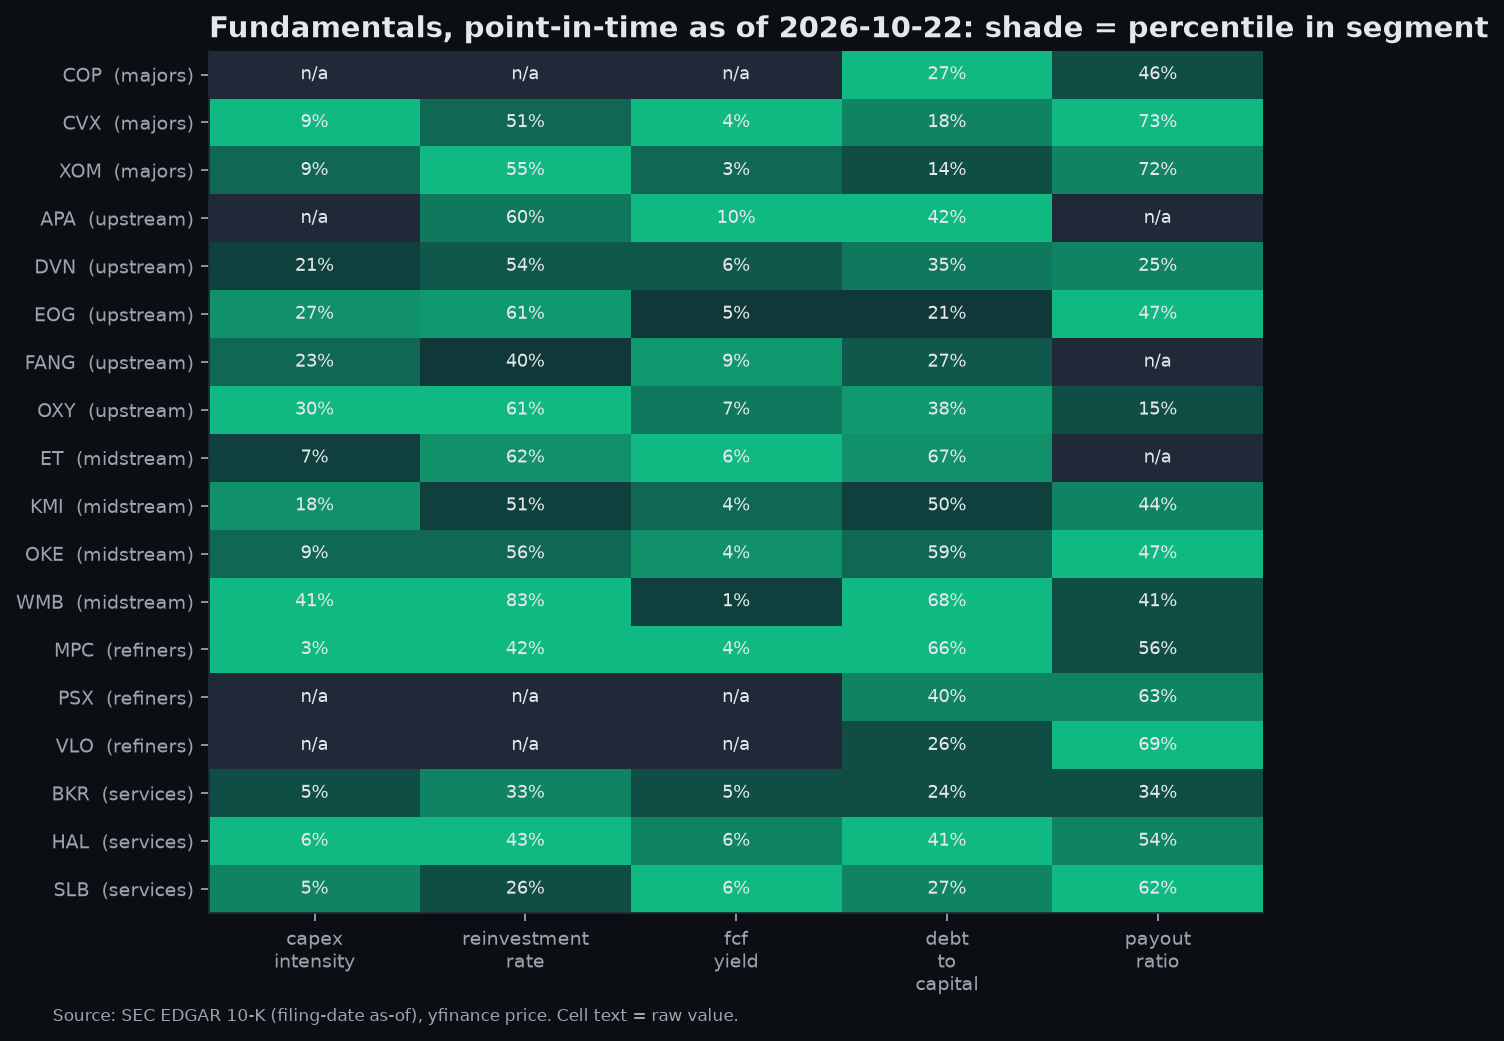

In [7]:
Image('../docs/img/fundamentals_heatmap.png')